**Looped transformers series (pure PyTorch):** [01 Universal Transformer](01_universal_transformer.ipynb) · [02 Adaptive Computation Time](02_act_halting.ipynb) · [03 Recurrent depth](03_recurrent_depth.ipynb) · [04 Fixed point (DEQ)](04_deq_fixed_point.ipynb) · [05 Mixture-of-Recursions](05_mixture_of_recursions.ipynb) · [06 Relaxed recursion](06_relaxed_recursion.ipynb) · [07 Scratchpad memory](07_scratchpad_memory.ipynb) · **08 Layer-sharing schedules**

# Looped transformers 08 - Layer-sharing schedules: which layers to reuse, and in what order

A normal transformer with depth $D$ owns $D$ distinct blocks. A fully looped transformer owns **one** block and applies it $D$ times. Between those two extremes is a whole design space: own $n$ distinct blocks ($1 \le n \le D$) and decide **which block runs at which depth position**. That decision is a *schedule*, a plain Python list such as `[0, 0, 1, 1]` or `[0, 1, 1, 0]`. In this notebook we write **one** model class whose behaviour is entirely set by that list, reproduce the schemes from Takase & Kiyono (2021) - SEQUENCE, CYCLE, CYCLE-REV - plus ALBERT-style full sharing and the "unshared first and last layer" variant used by Mixture-of-Recursions, and then measure, on real held-out text, what each scheme buys you in quality per parameter. Everything is built from scratch in pure PyTorch on a CPU.

| What you will learn | Where |
|---|---|
| How a single list of layer indices describes every sharing scheme | §1, §3 |
| Why sharing saves **parameters / memory** but **not compute** | §2, §8 |
| How gradients of a shared layer are *summed* over its uses (verified numerically) | §2, §3 |
| How to compare schemes fairly: same depth, same steps, 2 seeds, held-out bits/char | §8 |
| Which layers "get trained harder" and how similar consecutive hidden states are (CKA) | §7 |
| ALBERT's factorized embedding, and when it matters | §8 |

**Prerequisites:** Python, basic PyTorch (`nn.Module`, autograd, an optimizer loop), a rough idea of what self-attention does. Notebook 01 of this series derives attention by hand; here we use `nn.MultiheadAttention`.

**Estimated runtime:** about 7-10 minutes on a laptop CPU with 2 threads (the measured time is printed at the end).

## 1. Intuition

Think of the depth of a transformer as a **row of $D$ workstations on an assembly line**. A stacked transformer hires $D$ different workers. A fully looped one hires a single worker and walks the product past them $D$ times. Layer sharing asks: *if I can hire only $n$ workers, how should I seat them along the line?*

* **SEQUENCE** - each worker handles a contiguous stretch: `A A A B B B`. Worker A specialises in "early" processing, B in "late".
* **CYCLE** - workers take turns: `A B A B A B`. Every worker sees every stage of processing.
* **CYCLE-REV** - take turns, but mirror the last round: `A B A B | B A`. Takase & Kiyono found this best for machine translation.
* **FULL sharing (ALBERT / Universal Transformer)** - one worker for everything: `A A A A A A`.
* **MIDDLE-CYCLE (unshared first & last)** - a dedicated "intake" worker, a shared middle, a dedicated "output" worker: `A B B B B C`. The first layer reads raw embeddings and the last one writes for the output head, so these two jobs are arguably different from the rest. Mixture-of-Recursions (Bae et al., 2025) uses this "Middle-Cycle" layout.
* **STACKED** - the usual model, every position its own worker: `A B C D E F`.

The **key idea**: depth $D$ (how many times a block runs) sets the compute; the number of distinct blocks $n$ sets the parameter count. The schedule is the map between them.

```mermaid
flowchart TB
    tok["token ids  (B, L)"] --> emb["token + position embedding = h_0  (B, L, d)"]
    emb --> p1["depth position 1: run block s_1"]
    p1 --> p2["depth position 2: run block s_2"]
    p2 --> dots["..."]
    dots --> pD["depth position D: run block s_D"]
    pD --> head["final LayerNorm + linear head = logits  (B, L, V)"]
    bank[("layer bank: n distinct blocks  theta_0 ... theta_(n-1)")]
    bank -. "theta of s_1" .-> p1
    bank -. "theta of s_2" .-> p2
    bank -. "theta of s_D" .-> pD
    sched["schedule s = [s_1, ..., s_D]  e.g. [0, 1, 0, 1, 1, 0]"] --> bank
```

## 2. The math

Shapes: batch $B$, sequence length $L$, model width $d$, vocabulary $V$. Input token ids $x \in \{0..V-1\}^{B \times L}$.

**Embedding.** $E \in \mathbb{R}^{V \times d}$ is the token table, $P \in \mathbb{R}^{L_{max} \times d}$ the learned position table:
$$h_0 = E[x] + P[0{:}L] \quad\in \mathbb{R}^{B \times L \times d}.$$

**One pre-norm block** with parameters $\theta$ (two LayerNorms, attention, MLP):
$$h' = h + \mathrm{Attn}_\theta(\mathrm{LN}_1(h)), \qquad f_\theta(h) = h' + \mathrm{MLP}_\theta(\mathrm{LN}_2(h')), \qquad \mathrm{MLP}(z) = W_2\,\mathrm{GELU}(W_1 z + b_1) + b_2 .$$
Attention is **causal**: position $i$ may only attend to positions $j \le i$, so the model can be trained to predict token $i{+}1$ without seeing it.

**The schedule.** We own $n$ blocks $\theta_0, \dots, \theta_{n-1}$ and a schedule $s = (s_1, \dots, s_D)$ with $s_t \in \{0, \dots, n-1\}$. The forward pass is
$$h_t = f_{\theta_{s_t}}(h_{t-1}), \quad t = 1, \dots, D, \qquad \text{logits} = \mathrm{LN}_f(h_D)\,W_{out}^\top \in \mathbb{R}^{B \times L \times V}.$$
For depth $D$ and $n$ blocks (with $n$ dividing $D$ for SEQUENCE):

| scheme | $s_t$ (0-indexed $t$) | $D{=}6, n{=}2$ |
|---|---|---|
| stacked | $t$ (so $n = D$) | 0 1 2 3 4 5 |
| full | $0$ | 0 0 0 0 0 0 |
| sequence | $\lfloor t / (D/n) \rfloor$ | 0 0 0 1 1 1 |
| cycle | $t \bmod n$ | 0 1 0 1 0 1 |
| cycle-rev | $t \bmod n$ for $t < D-n$, then $n-1, \dots, 0$ | 0 1 0 1 1 0 |
| middle-cycle | $0$, then $1$ repeated $D{-}2$ times, then $2$ ($n{=}3$) | 0 1 1 1 1 2 |

**Parameters vs compute.** With $P_{blk}$ parameters per block,
$$\#\text{params} = n\,P_{blk} + \underbrace{V d + L_{max} d + 2d + V d}_{\text{embeddings, final norm, head}}, \qquad \text{FLOPs per token} \approx 2 \cdot D \cdot P_{blk} + \text{attention}(L).$$
The parameter count depends on $n$; the compute depends on $D$. **Sharing never reduces compute.**

**Gradients of a shared block are sums.** If block $j$ is used at the positions $T_j = \{t : s_t = j\}$, the chain rule gives
$$\frac{\partial \mathcal{L}}{\partial \theta_j} = \sum_{t \in T_j} \left.\frac{\partial \mathcal{L}}{\partial \theta}\right|_{\text{application } t}.$$
A block used 4 times collects 4 gradient contributions per step - we verify this identity numerically in §3 and look at its consequences in §7.

**Loss and metric.** Next-character cross-entropy in nats, $\mathcal{L} = -\frac{1}{BL}\sum \log p(x_{i+1} \mid x_{\le i})$; we report **bits per character** $\mathrm{bpc} = \mathcal{L} / \ln 2$ (lower is better; a uniform guess over $V$ characters costs $\log_2 V$).

**Linear CKA** (centered kernel alignment) measures how similar two sets of representations $X, Y \in \mathbb{R}^{N \times d}$ (rows = tokens, columns centered) are, ignoring rotations and scale:
$$\mathrm{CKA}(X, Y) = \frac{\lVert Y^\top X \rVert_F^2}{\lVert X^\top X \rVert_F \, \lVert Y^\top Y \rVert_F} = \frac{\mathrm{tr}(K_X H K_Y H)}{\sqrt{\mathrm{tr}(K_X H K_X H)\,\mathrm{tr}(K_Y H K_Y H)}},\quad K_X = XX^\top,\ H = I - \tfrac{1}{N}\mathbf{1}\mathbf{1}^\top .$$
CKA is 1 for identical representations (up to rotation/scale) and near 0 for unrelated ones.

## 3. Building blocks from scratch

### 3.1 Setup
Only the standard library, `torch`, `numpy` and `matplotlib`. We pin the CPU to 2 threads (other jobs share the machine) and fix seeds.

In [1]:
import math
import random
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.set_num_threads(2)
NOTEBOOK_START = time.time()


def set_seed(seed: int) -> None:
    # Python, NumPy and PyTorch each keep their own random generator.
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed(0)
print("torch", torch.__version__, "| threads:", torch.get_num_threads())

torch 2.13.0 | threads: 2


### 3.2 Data and a character tokenizer
Two corpora (shared by the whole series):
* **Toy corpus** - 4 sentences of 48 characters that differ only at two "choice points" (`model`/`robot`, `write`/`spell`). Small enough to see what the model learns.
* **Docstring corpus** - real English documentation text that ships with Python. We split it 90/10 **by position** (the validation text comes after the training text, so no window overlaps).

In [2]:
TOY_CORPUS = [
    "the tiny model learned to write this sentence :)",
    "the tiny robot learned to write this sentence :)",
    "the tiny model learned to spell this sentence :)",
    "the tiny robot learned to spell this sentence :)",
]  # 48 chars each; two genuine choice points: model/robot and write/spell


def docstring_corpus() -> str:
    """Real English text that ships with Python: docstrings of standard-library modules."""
    import importlib, inspect, re
    mods = ["collections", "itertools", "functools", "json", "re", "string", "textwrap", "pathlib",
            "datetime", "statistics", "random", "heapq", "bisect", "typing", "dataclasses", "argparse",
            "logging", "enum", "fractions", "decimal", "csv", "shutil", "tempfile", "contextlib", "abc",
            "copy", "pprint", "difflib", "calendar", "zipfile"]
    docs = []
    for m in mods:
        for _, obj in inspect.getmembers(importlib.import_module(m)):
            d = inspect.getdoc(obj)
            if d and len(d) > 60 and (inspect.isfunction(obj) or inspect.isclass(obj) or inspect.ismethod(obj)):
                docs.append(d)
    return re.sub(r"\s+", " ", " ".join(dict.fromkeys(docs)))


DOC_TEXT = docstring_corpus()
split_at = int(0.9 * len(DOC_TEXT))
TRAIN_TEXT, VAL_TEXT = DOC_TEXT[:split_at], DOC_TEXT[split_at:]
print(f"docstring corpus: {len(DOC_TEXT):,} characters  (train {len(TRAIN_TEXT):,} / val {len(VAL_TEXT):,})")
print("sample:", DOC_TEXT[:160], "...")
assert all(len(s) == 48 for s in TOY_CORPUS)

docstring corpus: 142,997 characters  (train 128,697 / val 14,300)
sample: A ChainMap groups multiple dicts (or other mappings) together to create a single, updateable view. The underlying mappings are stored in a list. That list is pu ...


In [3]:
class CharTokenizer:
    # Every distinct character becomes one integer id.
    def __init__(self, text: str) -> None:
        self.chars = sorted(set(text))
        self.stoi = {c: i for i, c in enumerate(self.chars)}
        self.itos = {i: c for i, c in enumerate(self.chars)}

    @property
    def vocab_size(self) -> int:
        return len(self.chars)

    def encode(self, s: str) -> torch.Tensor:
        return torch.tensor([self.stoi[c] for c in s], dtype=torch.long)

    def decode(self, ids: torch.Tensor) -> str:
        return "".join(self.itos[int(i)] for i in ids)


tok = CharTokenizer(DOC_TEXT + "".join(TOY_CORPUS))
train_ids = tok.encode(TRAIN_TEXT)
val_ids = tok.encode(VAL_TEXT)
assert tok.decode(tok.encode(TOY_CORPUS[0])) == TOY_CORPUS[0]
print("vocab size V =", tok.vocab_size, f"-> a uniform guess costs log2(V) = {math.log2(tok.vocab_size):.2f} bits/char")

vocab size V = 98 -> a uniform guess costs log2(V) = 6.61 bits/char


In [4]:
SEQ_LEN = 64  # we train on random 64-character windows


def get_batch(ids: torch.Tensor, batch_size: int, seq_len: int, gen: torch.Generator) -> tuple[torch.Tensor, torch.Tensor]:
    # Pick random start offsets; target = input shifted by one character.
    starts = torch.randint(0, len(ids) - seq_len - 1, (batch_size,), generator=gen)
    x = torch.stack([ids[s : s + seq_len] for s in starts])
    y = torch.stack([ids[s + 1 : s + seq_len + 1] for s in starts])
    return x, y


xb, yb = get_batch(train_ids, 4, SEQ_LEN, torch.Generator().manual_seed(0))
print("x:", tuple(xb.shape), "y:", tuple(yb.shape))
print(repr(tok.decode(xb[0])))
print(repr(tok.decode(yb[0])))
assert torch.equal(xb[:, 1:], yb[:, :-1])  # y really is x shifted by one

x: (4, 64) y: (4, 64)
'g how the file is to be opened. Accepts the same values as the b'
' how the file is to be opened. Accepts the same values as the bu'


### 3.3 The causal mask
`nn.MultiheadAttention` takes a boolean `attn_mask` of shape $(L, L)$ where **`True` means "not allowed to attend"**. For causal language modelling we forbid every key position $j > i$ for query $i$, i.e. the strict upper triangle.

In [5]:
def causal_mask(seq_len: int) -> torch.Tensor:
    # True above the diagonal = query i must NOT look at future key j > i.
    return torch.triu(torch.ones(seq_len, seq_len, dtype=torch.bool), diagonal=1)


print(causal_mask(5).int())
assert causal_mask(5)[2, 3] and not causal_mask(5)[3, 2]

tensor([[0, 1, 1, 1, 1],
        [0, 0, 1, 1, 1],
        [0, 0, 0, 1, 1],
        [0, 0, 0, 0, 1],
        [0, 0, 0, 0, 0]], dtype=torch.int32)


### 3.4 One pre-norm transformer block
This is the series' reference block: LayerNorm -> causal self-attention -> residual, LayerNorm -> MLP(GELU) -> residual. It is the *only* kind of layer in the model; sharing decides how many copies of it exist.

In [6]:
class Block(nn.Module):
    def __init__(self, d_model: int, n_heads: int, mlp_ratio: int = 4) -> None:
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = nn.MultiheadAttention(d_model, n_heads, batch_first=True)
        self.ln2 = nn.LayerNorm(d_model)
        self.mlp = nn.Sequential(
            nn.Linear(d_model, mlp_ratio * d_model),
            nn.GELU(),
            nn.Linear(mlp_ratio * d_model, d_model),
        )

    def forward(self, x: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
        h = self.ln1(x)
        attn_out, _ = self.attn(h, h, h, attn_mask=mask, need_weights=False)
        x = x + attn_out                  # residual 1
        x = x + self.mlp(self.ln2(x))     # residual 2
        return x


blk = Block(d_model=64, n_heads=4)
toy_x = torch.randn(2, 10, 64)
out = blk(toy_x, causal_mask(10))
print("block in", tuple(toy_x.shape), "-> out", tuple(out.shape))
print("parameters per block P_blk =", sum(p.numel() for p in blk.parameters()))
assert out.shape == toy_x.shape

block in (2, 10, 64) -> out (2, 10, 64)
parameters per block P_blk = 49984


### 3.5 Schedules are just lists
Each function below returns a list of length $D$; entry $t$ is the id of the block that runs at depth position $t$.

In [7]:
def schedule_stacked(depth: int) -> list[int]:
    return list(range(depth))


def schedule_full(depth: int) -> list[int]:
    return [0] * depth


def schedule_sequence(n_layers: int, depth: int) -> list[int]:
    # Each block handles a contiguous stretch of depth/n positions: A A A B B B
    assert depth % n_layers == 0, "SEQUENCE needs n to divide D"
    repeat = depth // n_layers
    return [t // repeat for t in range(depth)]


def schedule_cycle(n_layers: int, depth: int) -> list[int]:
    # Blocks take turns: A B A B A B
    return [t % n_layers for t in range(depth)]


def schedule_cycle_rev(n_layers: int, depth: int) -> list[int]:
    # Cycle for the first D-n positions, then the last n positions in reverse order: A B A B | B A
    head = [t % n_layers for t in range(depth - n_layers)]
    tail = list(reversed(range(n_layers)))
    return head + tail


def schedule_middle_cycle(depth: int) -> list[int]:
    # Unshared first and last block, one shared block in the middle: A B B B B C
    return [0] + [1] * (depth - 2) + [2]


def n_layers_of(schedule: list[int]) -> int:
    return len(set(schedule))


for name, s in [("stacked", schedule_stacked(6)), ("full", schedule_full(6)),
                ("sequence n=2", schedule_sequence(2, 6)), ("cycle n=2", schedule_cycle(2, 6)),
                ("cycle_rev n=2", schedule_cycle_rev(2, 6)), ("cycle_rev n=3", schedule_cycle_rev(3, 6)),
                ("middle_cycle", schedule_middle_cycle(6))]:
    print(f"{name:14s} {s}   n = {n_layers_of(s)}")
assert schedule_cycle_rev(3, 6) == [0, 1, 2, 2, 1, 0]  # Takase & Kiyono's example (1 2 3 3 2 1)
assert schedule_sequence(3, 6) == [0, 0, 1, 1, 2, 2]

stacked        [0, 1, 2, 3, 4, 5]   n = 6
full           [0, 0, 0, 0, 0, 0]   n = 1
sequence n=2   [0, 0, 0, 1, 1, 1]   n = 2
cycle n=2      [0, 1, 0, 1, 0, 1]   n = 2
cycle_rev n=2  [0, 1, 0, 1, 1, 0]   n = 2
cycle_rev n=3  [0, 1, 2, 2, 1, 0]   n = 3
middle_cycle   [0, 1, 1, 1, 1, 2]   n = 3


### 3.6 Picture of the schedules
Rows are schemes, columns are depth positions, the colour/letter is the block that runs there. **Same colour in a row = same weights.**

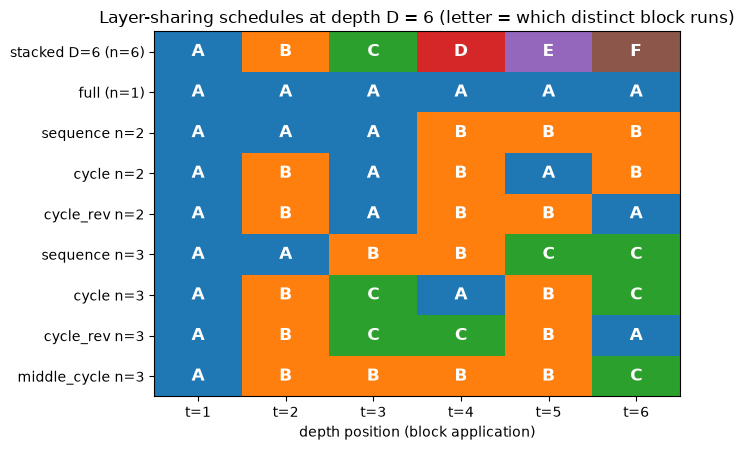

In [8]:
DEPTH = 6
SCHEDULES = {
    "stacked D=6 (n=6)": schedule_stacked(6),
    "full (n=1)": schedule_full(6),
    "sequence n=2": schedule_sequence(2, DEPTH),
    "cycle n=2": schedule_cycle(2, DEPTH),
    "cycle_rev n=2": schedule_cycle_rev(2, DEPTH),
    "sequence n=3": schedule_sequence(3, DEPTH),
    "cycle n=3": schedule_cycle(3, DEPTH),
    "cycle_rev n=3": schedule_cycle_rev(3, DEPTH),
    "middle_cycle n=3": schedule_middle_cycle(DEPTH),
}

grid = np.array(list(SCHEDULES.values()))
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.imshow(grid, cmap="tab10", vmin=0, vmax=9, aspect="auto")
for r in range(grid.shape[0]):
    for c in range(grid.shape[1]):
        ax.text(c, r, "ABCDEF"[grid[r, c]], ha="center", va="center", color="white", fontsize=12, fontweight="bold")
ax.set_yticks(range(len(SCHEDULES)), labels=list(SCHEDULES.keys()))
ax.set_xticks(range(DEPTH), labels=[f"t={t + 1}" for t in range(DEPTH)])
ax.set_xlabel("depth position (block application)")
ax.set_title("Layer-sharing schedules at depth D = 6 (letter = which distinct block runs)")
plt.tight_layout()
plt.show()

## 4. The full model

One class, `ScheduledLM`. It owns `n_layers` blocks in an `nn.ModuleList` and loops over the schedule. Nothing else changes between schemes. `return_hidden=True` also returns $[h_0, h_1, \dots, h_D]$ so we can look inside later.

In [9]:
class ScheduledLM(nn.Module):
    def __init__(self, vocab_size: int, d_model: int, n_heads: int, schedule: list[int], max_len: int = 64) -> None:
        super().__init__()
        self.schedule = list(schedule)
        self.n_layers = n_layers_of(self.schedule)
        # Every owned block must actually be used, otherwise it is dead weight.
        assert sorted(set(self.schedule)) == list(range(self.n_layers)), "schedule must use ids 0..n-1"
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Embedding(max_len, d_model)
        self.layers = nn.ModuleList([Block(d_model, n_heads) for _ in range(self.n_layers)])
        self.ln_f = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size, bias=False)
        self.register_buffer("mask", causal_mask(max_len), persistent=False)

    def forward(self, idx: torch.Tensor, return_hidden: bool = False):
        batch, seq_len = idx.shape
        positions = torch.arange(seq_len, device=idx.device)
        x = self.tok_emb(idx) + self.pos_emb(positions)   # h_0: (B, L, d)
        mask = self.mask[:seq_len, :seq_len]
        hidden = [x]
        for layer_id in self.schedule:                    # the ONLY place the schedule is used
            x = self.layers[layer_id](x, mask)
            hidden.append(x)
        logits = self.head(self.ln_f(x))                  # (B, L, V)
        if return_hidden:
            return logits, hidden
        return logits


def count_params(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters())


D_MODEL, N_HEADS = 64, 4
m = ScheduledLM(tok.vocab_size, D_MODEL, N_HEADS, schedule_cycle_rev(2, 6))
logits, hidden = m(xb, return_hidden=True)
print("logits", tuple(logits.shape), "| hidden states:", len(hidden), "x", tuple(hidden[0].shape))
assert logits.shape == (4, SEQ_LEN, tok.vocab_size) and len(hidden) == 6 + 1

logits (4, 64, 98) | hidden states: 7 x (4, 64, 64)


### 4.1 Correctness checks
1. **Causality**: changing future characters must not change earlier logits.
2. **Same $n$ => same parameter count**, regardless of the order.
3. **The loop equals a hand-unrolled forward** for CYCLE-REV `A B A B B A`.
4. **Shared gradient = sum of per-application gradients**: copy the shared weights into an *untied* stacked model, backprop the same loss through both, and check that the gradient of shared block A equals the sum of the gradients of the untied copies sitting at A's positions.

In [10]:
set_seed(0)
m = ScheduledLM(tok.vocab_size, D_MODEL, N_HEADS, schedule_cycle_rev(2, 6)).eval()

# 1. causality: perturb the second half of the sequence only.
x1 = xb.clone()
x2 = xb.clone()
x2[:, 40:] = torch.randint(0, tok.vocab_size, (4, SEQ_LEN - 40))
with torch.no_grad():
    diff_past = (m(x1)[:, :40] - m(x2)[:, :40]).abs().max().item()
    diff_future = (m(x1)[:, 40:] - m(x2)[:, 40:]).abs().max().item()
print(f"max |logit change| at positions < 40: {diff_past:.2e}   at positions >= 40: {diff_future:.2e}")
assert diff_past < 1e-5 and diff_future > 1e-3

# 2. parameter counts depend only on n.
for n in (2, 3):
    counts = {name: count_params(ScheduledLM(tok.vocab_size, D_MODEL, N_HEADS, fn(n, 6)))
              for name, fn in [("sequence", schedule_sequence), ("cycle", schedule_cycle), ("cycle_rev", schedule_cycle_rev)]}
    print(f"n={n}:", counts)
    assert len(set(counts.values())) == 1
assert count_params(ScheduledLM(tok.vocab_size, D_MODEL, N_HEADS, schedule_middle_cycle(6))) == counts["cycle"]

# 3. hand-unrolled forward for schedule [0, 1, 0, 1, 1, 0].
with torch.no_grad():
    A, Bk = m.layers[0], m.layers[1]
    mask = m.mask[:SEQ_LEN, :SEQ_LEN]
    h = m.tok_emb(xb) + m.pos_emb(torch.arange(SEQ_LEN))
    h = A(h, mask)
    h = Bk(h, mask)
    h = A(h, mask)
    h = Bk(h, mask)
    h = Bk(h, mask)
    h = A(h, mask)
    manual_logits = m.head(m.ln_f(h))
    max_err = (manual_logits - m(xb)).abs().max().item()
print(f"loop vs hand-unrolled: max abs difference = {max_err:.2e}")
assert max_err < 1e-6

max |logit change| at positions < 40: 0.00e+00   at positions >= 40: 2.16e+00
n=2: {'sequence': 116736, 'cycle': 116736, 'cycle_rev': 116736}
n=3: {'sequence': 166720, 'cycle': 166720, 'cycle_rev': 166720}
loop vs hand-unrolled: max abs difference = 0.00e+00


In [11]:
# 4. gradient of a shared block = sum over its applications.
set_seed(1)
shared = ScheduledLM(tok.vocab_size, D_MODEL, N_HEADS, schedule_cycle(2, 6))
untied = ScheduledLM(tok.vocab_size, D_MODEL, N_HEADS, schedule_stacked(6))
# Copy weights: untied block t gets the weights of shared block s_t; embeddings/head identical.
untied.tok_emb.load_state_dict(shared.tok_emb.state_dict())
untied.pos_emb.load_state_dict(shared.pos_emb.state_dict())
untied.ln_f.load_state_dict(shared.ln_f.state_dict())
untied.head.load_state_dict(shared.head.state_dict())
for t, layer_id in enumerate(shared.schedule):
    untied.layers[t].load_state_dict(shared.layers[layer_id].state_dict())

for model in (shared, untied):
    loss = F.cross_entropy(model(xb).reshape(-1, tok.vocab_size), yb.reshape(-1))
    loss.backward()
    print(type(model).__name__, model.schedule, f"loss = {loss.item():.6f}")

for layer_id in range(shared.n_layers):
    positions = [t for t, s in enumerate(shared.schedule) if s == layer_id]
    g_shared = shared.layers[layer_id].mlp[0].weight.grad
    g_sum = sum(untied.layers[t].mlp[0].weight.grad for t in positions)
    err = (g_shared - g_sum).abs().max().item()
    print(f"block {'AB'[layer_id]} used at positions {positions}: |grad_shared - sum(grad_untied)| = {err:.2e}")
    assert err < 1e-5
# Every block receives a non-zero gradient.
assert all(p.grad is not None and p.grad.abs().sum() > 0 for p in shared.layers.parameters())

ScheduledLM [0, 1, 0, 1, 0, 1] loss = 4.671219


ScheduledLM [0, 1, 2, 3, 4, 5] loss = 4.671219
block A used at positions [0, 2, 4]: |grad_shared - sum(grad_untied)| = 1.86e-09
block B used at positions [1, 3, 5]: |grad_shared - sum(grad_untied)| = 1.86e-09


### 4.2 Parameters vs compute
At $d = 64$ every configuration below runs the same kind of block; only $n$ (owned) and $D$ (applied) change. "Block-applications" is proportional to the FLOPs spent in the transformer body.

In [12]:
P_BLK = sum(p.numel() for p in Block(D_MODEL, N_HEADS).parameters())
rows = []
for name, sched in {"stacked D=2": schedule_stacked(2), "stacked D=3": schedule_stacked(3), **SCHEDULES}.items():
    model = ScheduledLM(tok.vocab_size, D_MODEL, N_HEADS, sched)
    rows.append((name, n_layers_of(sched), len(sched), count_params(model), n_layers_of(sched) * P_BLK))
print(f"{'config':20s} {'n owned':>8s} {'D applied':>10s} {'total params':>13s} {'block params':>13s} {'body FLOPs/token':>17s}")
for name, n, d, total, body in rows:
    print(f"{name:20s} {n:8d} {d:10d} {total:13,d} {body:13,d} {2 * d * P_BLK:17,d}")

config                n owned  D applied  total params  block params  body FLOPs/token
stacked D=2                 2          2       116,736        99,968           199,936
stacked D=3                 3          3       166,720       149,952           299,904
stacked D=6 (n=6)           6          6       316,672       299,904           599,808
full (n=1)                  1          6        66,752        49,984           599,808
sequence n=2                2          6       116,736        99,968           599,808
cycle n=2                   2          6       116,736        99,968           599,808
cycle_rev n=2               2          6       116,736        99,968           599,808
sequence n=3                3          6       166,720       149,952           599,808
cycle n=3                   3          6       166,720       149,952           599,808
cycle_rev n=3               3          6       166,720       149,952           599,808
middle_cycle n=3            3          6   

## 5. Data recap and 6. The training loop

The training loop is written out explicitly: sample a batch, forward, cross-entropy, backward, **record per-block gradient norms** (we need them in §7), clip, step. Learning rate: linear warm-up then cosine decay to 10%. Evaluation runs over fixed, non-overlapping validation windows so every model is scored on exactly the same text.

In [13]:
def lr_at(step: int, total_steps: int, base_lr: float, warmup: int) -> float:
    if step < warmup:
        return base_lr * (step + 1) / warmup
    progress = (step - warmup) / max(1, total_steps - warmup)
    return base_lr * (0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * progress)))


def block_grad_norms(model: ScheduledLM) -> list[float]:
    # L2 norm of the full gradient of each owned block (before clipping).
    norms = []
    for layer in model.layers:
        sq = sum(p.grad.pow(2).sum() for p in layer.parameters() if p.grad is not None)
        norms.append(float(torch.sqrt(sq)))
    return norms


@torch.no_grad()
def evaluate_bpc(model: ScheduledLM, ids: torch.Tensor, seq_len: int = SEQ_LEN, max_windows: int = 512, batch_size: int = 128) -> float:
    model.eval()
    n_windows = min(max_windows, (len(ids) - 1) // seq_len)
    starts = [i * seq_len for i in range(n_windows)]
    total_nats, total_tokens = 0.0, 0
    for i in range(0, n_windows, batch_size):
        chunk = starts[i : i + batch_size]
        x = torch.stack([ids[s : s + seq_len] for s in chunk])
        y = torch.stack([ids[s + 1 : s + seq_len + 1] for s in chunk])
        loss = F.cross_entropy(model(x).reshape(-1, model.head.out_features), y.reshape(-1), reduction="sum")
        total_nats += loss.item()
        total_tokens += y.numel()
    model.train()
    return total_nats / total_tokens / math.log(2)


def train_lm(model: ScheduledLM, batch_fn, steps: int, base_lr: float, seed: int, warmup: int = 50) -> dict:
    gen = torch.Generator().manual_seed(seed)   # same data order for every model with the same seed
    opt = torch.optim.AdamW(model.parameters(), lr=base_lr, betas=(0.9, 0.98), weight_decay=0.01)
    history = {"loss": [], "grad_norms": []}
    model.train()
    start = time.time()
    for step in range(steps):
        for group in opt.param_groups:
            group["lr"] = lr_at(step, steps, base_lr, warmup)
        x, y = batch_fn(gen)
        logits = model(x)
        loss = F.cross_entropy(logits.reshape(-1, logits.shape[-1]), y.reshape(-1))
        opt.zero_grad(set_to_none=True)
        loss.backward()
        history["grad_norms"].append(block_grad_norms(model))
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        history["loss"].append(loss.item())
    history["seconds"] = time.time() - start
    return history

### 6.1 Warm-up on the toy corpus
Each batch is all four sentences (input = first 47 characters, target = last 47). Only the two choice points are genuinely uncertain, each a fair coin, so the best achievable loss is $2 \ln 2 / 47 \approx 0.0295$ nats per character. We train a stacked 6-layer model, a fully shared one and a CYCLE n=2 model for 300 steps.

stacked D=6  params 316,672  final loss 0.0306  (1.7s)


full (n=1)   params  66,752  final loss 0.0305  (1.4s)


cycle n=2    params 116,736  final loss 0.0306  (1.6s)


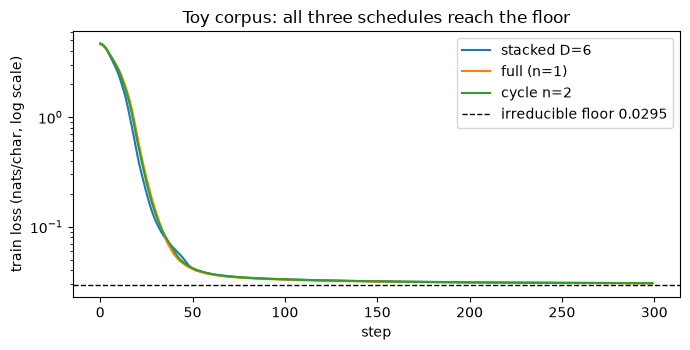

In [14]:
toy_ids = torch.stack([tok.encode(s) for s in TOY_CORPUS])   # (4, 48)
TOY_X, TOY_Y = toy_ids[:, :-1], toy_ids[:, 1:]
TOY_FLOOR = 2 * math.log(2) / 47


def toy_batch(gen: torch.Generator) -> tuple[torch.Tensor, torch.Tensor]:
    return TOY_X, TOY_Y


toy_models, toy_hist = {}, {}
for name, sched in [("stacked D=6", schedule_stacked(6)), ("full (n=1)", schedule_full(6)), ("cycle n=2", schedule_cycle(2, 6))]:
    set_seed(0)
    toy_models[name] = ScheduledLM(tok.vocab_size, D_MODEL, N_HEADS, sched, max_len=SEQ_LEN)
    toy_hist[name] = train_lm(toy_models[name], toy_batch, steps=300, base_lr=3e-3, seed=0, warmup=20)
    print(f"{name:12s} params {count_params(toy_models[name]):7,d}  final loss {toy_hist[name]['loss'][-1]:.4f}  "
          f"({toy_hist[name]['seconds']:.1f}s)")

fig, ax = plt.subplots(figsize=(7, 3.6))
for name, h in toy_hist.items():
    ax.plot(h["loss"], label=name)
ax.axhline(TOY_FLOOR, color="k", ls="--", lw=1, label=f"irreducible floor {TOY_FLOOR:.4f}")
ax.set_yscale("log")
ax.set_xlabel("step")
ax.set_ylabel("train loss (nats/char, log scale)")
ax.set_title("Toy corpus: all three schedules reach the floor")
ax.legend()
plt.tight_layout()
plt.show()

In [15]:
@torch.no_grad()
def next_char_probs(model: ScheduledLM, prefix: str, chars: str) -> dict[str, float]:
    model.eval()
    probs = F.softmax(model(tok.encode(prefix)[None])[0, -1], dim=-1)
    model.train()
    return {c: round(float(probs[tok.stoi[c]]), 3) for c in chars}


for name, model in toy_models.items():
    p1 = next_char_probs(model, "the tiny ", "mr")
    p2 = next_char_probs(model, "the tiny robot learned to ", "ws")
    p3 = next_char_probs(model, "the tiny robot learned to w", "r")
    print(f"{name:12s} P(model|robot) after 'the tiny ' = {p1}   P(write|spell) = {p2}   P('r' after '...to w') = {p3}")

stacked D=6  P(model|robot) after 'the tiny ' = {'m': 0.499, 'r': 0.499}   P(write|spell) = {'w': 0.498, 's': 0.499}   P('r' after '...to w') = {'r': 0.999}
full (n=1)   P(model|robot) after 'the tiny ' = {'m': 0.498, 'r': 0.499}   P(write|spell) = {'w': 0.499, 's': 0.499}   P('r' after '...to w') = {'r': 0.998}
cycle n=2    P(model|robot) after 'the tiny ' = {'m': 0.498, 'r': 0.499}   P(write|spell) = {'w': 0.498, 's': 0.499}   P('r' after '...to w') = {'r': 0.999}


_(conclusions are written after the first run)_

### 6.2 Training on the docstring corpus
Main setting, identical for every configuration: $d = 64$, 4 heads, depth $D = 6$ block applications, batch 32 windows of 64 characters, AdamW with peak learning rate $2\times10^{-3}$, `STEPS` steps, 2 seeds (seed = initialisation **and** data order). We add two cheap reference points: **stacked $D = 2$** and **stacked $D = 3$**, which own the same number of blocks as the $n = 2$ / $n = 3$ shared models but use one third / one half of the compute. They answer the question *"is reusing layers better than just having a shallower model with the same parameters?"*.

This cell is the expensive one (most of the notebook's runtime).

In [16]:
STEPS = 700
BATCH = 32
BASE_LR = 2e-3
SEEDS = [0, 1]

EXPERIMENTS = {
    "stacked D=2": schedule_stacked(2),
    "stacked D=3": schedule_stacked(3),
    **SCHEDULES,
}


def doc_batch(gen: torch.Generator) -> tuple[torch.Tensor, torch.Tensor]:
    return get_batch(train_ids, BATCH, SEQ_LEN, gen)


results = {}   # (name, seed) -> dict
for seed in SEEDS:
    for name, sched in EXPERIMENTS.items():
        set_seed(seed)
        model = ScheduledLM(tok.vocab_size, D_MODEL, N_HEADS, sched)
        hist = train_lm(model, doc_batch, steps=STEPS, base_lr=BASE_LR, seed=seed)
        val_bpc = evaluate_bpc(model, val_ids)
        results[(name, seed)] = {"model": model, "hist": hist, "val_bpc": val_bpc, "params": count_params(model)}
        print(f"seed {seed} | {name:18s} | params {count_params(model):7,d} | val bpc {val_bpc:.4f} | {hist['seconds']:5.1f}s")

seed 0 | stacked D=2        | params 116,736 | val bpc 3.6989 |   7.4s


seed 0 | stacked D=3        | params 166,720 | val bpc 3.5948 |  27.3s


seed 0 | stacked D=6 (n=6)  | params 316,672 | val bpc 3.4436 |  56.2s


seed 0 | full (n=1)         | params  66,752 | val bpc 3.7251 | 101.7s


seed 0 | sequence n=2       | params 116,736 | val bpc 3.5678 | 138.6s


seed 0 | cycle n=2          | params 116,736 | val bpc 3.6129 | 108.5s


... (12 outputs left out)

seed 1 | sequence n=3       | params 166,720 | val bpc 3.5020 |  16.3s


seed 1 | cycle n=3          | params 166,720 | val bpc 3.5509 |  16.3s


seed 1 | cycle_rev n=3      | params 166,720 | val bpc 3.5528 |  16.4s


seed 1 | middle_cycle n=3   | params 166,720 | val bpc 3.5275 |  16.5s


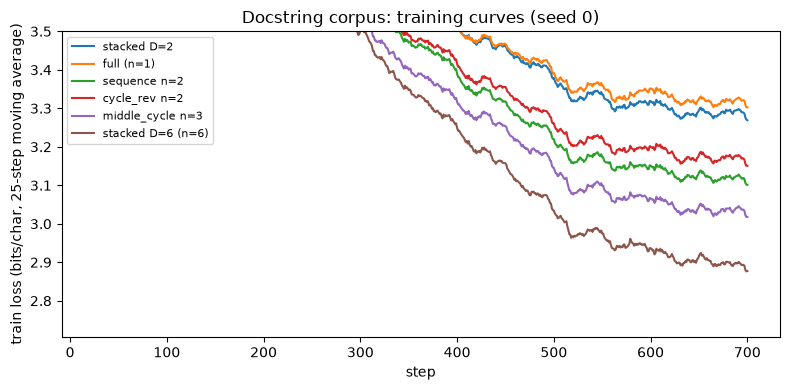

In [17]:
fig, ax = plt.subplots(figsize=(8, 4))
window = 25
for name in ["stacked D=2", "full (n=1)", "sequence n=2", "cycle_rev n=2", "middle_cycle n=3", "stacked D=6 (n=6)"]:
    loss = np.array(results[(name, 0)]["hist"]["loss"]) / math.log(2)
    smooth = np.convolve(loss, np.ones(window) / window, mode="valid")
    ax.plot(np.arange(len(smooth)) + window, smooth, label=name)
ax.set_xlabel("step")
ax.set_ylabel("train loss (bits/char, 25-step moving average)")
ax.set_title("Docstring corpus: training curves (seed 0)")
ax.set_ylim(top=3.5)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 7. Look inside

### 7.1 Who gets trained harder? Per-block gradient norms
We recorded $\lVert \partial \mathcal{L} / \partial \theta_j \rVert_2$ for every owned block at every step (before clipping). From §2, a block used $k$ times sums $k$ contributions, so we expect bigger norms for blocks with more uses. We plot the average over the last 500 steps (seed 0). Bars are labelled with the number of uses.

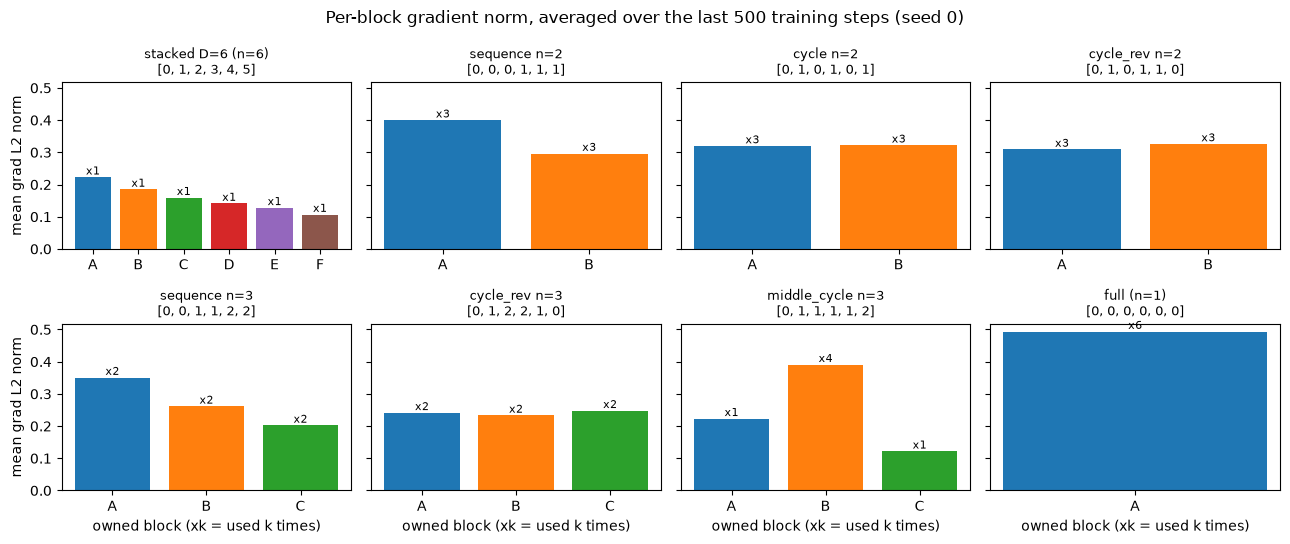

stacked D=6 (n=6)  grad norm per block: [0.223 0.185 0.159 0.141 0.128 0.107]  per use: [0.223 0.185 0.159 0.141 0.128 0.107]
sequence n=2       grad norm per block: [0.4   0.296]  per use: [0.133 0.099]
cycle n=2          grad norm per block: [0.32  0.322]  per use: [0.107 0.107]
cycle_rev n=2      grad norm per block: [0.309 0.326]  per use: [0.103 0.109]
sequence n=3       grad norm per block: [0.351 0.261 0.202]  per use: [0.175 0.131 0.101]
cycle_rev n=3      grad norm per block: [0.241 0.233 0.248]  per use: [0.121 0.117 0.124]
middle_cycle n=3   grad norm per block: [0.223 0.391 0.122]  per use: [0.223 0.098 0.122]
full (n=1)         grad norm per block: [0.493]  per use: [0.082]


In [18]:
inspect_names = ["stacked D=6 (n=6)", "sequence n=2", "cycle n=2", "cycle_rev n=2", "sequence n=3", "cycle_rev n=3", "middle_cycle n=3", "full (n=1)"]
fig, axes = plt.subplots(2, 4, figsize=(13, 5.5), sharey=True)
grad_table = {}
for ax, name in zip(axes.ravel(), inspect_names):
    sched = EXPERIMENTS[name]
    norms = np.array(results[(name, 0)]["hist"]["grad_norms"])[-500:].mean(axis=0)
    uses = [sched.count(j) for j in range(len(norms))]
    grad_table[name] = (norms, uses)
    ax.bar(range(len(norms)), norms, color=[plt.cm.tab10(j) for j in range(len(norms))])
    for j, (v, u) in enumerate(zip(norms, uses)):
        ax.text(j, v, f"x{u}", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(range(len(norms)), labels=["ABCDEF"[j] for j in range(len(norms))])
    ax.set_title(f"{name}\n{sched}", fontsize=9)
for ax in axes[:, 0]:
    ax.set_ylabel("mean grad L2 norm")
for ax in axes[1]:
    ax.set_xlabel("owned block (xk = used k times)")
fig.suptitle("Per-block gradient norm, averaged over the last 500 training steps (seed 0)")
plt.tight_layout()
plt.show()

for name, (norms, uses) in grad_table.items():
    per_use = norms / np.array(uses)
    print(f"{name:18s} grad norm per block: {np.round(norms, 3)}  per use: {np.round(per_use, 3)}")

_(conclusions are written after the first run)_

### 7.2 How much does each depth position change the representation? (CKA)
We run 64 validation windows (4,096 tokens) through each trained model, collect $h_0, \dots, h_6$, and compute linear CKA between every pair of depth positions. First we check the CKA implementation: the feature-space and kernel-space formulas from §2 must agree, CKA must be 1 for a rotated + rescaled copy, and near 0 for independent noise.

In [19]:
def linear_cka(X: torch.Tensor, Y: torch.Tensor) -> float:
    # Feature-space formula: ||Y^T X||_F^2 / (||X^T X||_F ||Y^T Y||_F), columns centered.
    X = X - X.mean(0, keepdim=True)
    Y = Y - Y.mean(0, keepdim=True)
    num = (Y.T @ X).pow(2).sum()
    den = torch.linalg.norm(X.T @ X) * torch.linalg.norm(Y.T @ Y)
    return float(num / den)


def linear_cka_kernel(X: torch.Tensor, Y: torch.Tensor) -> float:
    # Kernel-space formula with the centering matrix H (only for small N: it builds N x N matrices).
    n = X.shape[0]
    H = torch.eye(n, dtype=X.dtype) - torch.ones(n, n, dtype=X.dtype) / n
    KX, KY = X @ X.T, Y @ Y.T
    hsic_xy = torch.trace(KX @ H @ KY @ H)
    hsic_xx = torch.trace(KX @ H @ KX @ H)
    hsic_yy = torch.trace(KY @ H @ KY @ H)
    return float(hsic_xy / torch.sqrt(hsic_xx * hsic_yy))


g = torch.Generator().manual_seed(0)
Xa = torch.randn(300, 64, generator=g, dtype=torch.float64)
Ya = torch.tanh(Xa @ torch.randn(64, 64, generator=g, dtype=torch.float64)) + 0.5 * torch.randn(300, 64, generator=g, dtype=torch.float64)
Q, _ = torch.linalg.qr(torch.randn(64, 64, generator=g, dtype=torch.float64))
print(f"feature formula {linear_cka(Xa, Ya):.6f}   kernel formula {linear_cka_kernel(Xa, Ya):.6f}")
print(f"CKA(X, 3.7 * X Q) = {linear_cka(Xa, 3.7 * Xa @ Q):.6f}   CKA(X, noise) = {linear_cka(Xa, torch.randn(300, 64, generator=g, dtype=torch.float64)):.4f}")
assert abs(linear_cka(Xa, Ya) - linear_cka_kernel(Xa, Ya)) < 1e-9
assert abs(linear_cka(Xa, 3.7 * Xa @ Q) - 1.0) < 1e-9

feature formula 0.546299   kernel formula 0.546299
CKA(X, 3.7 * X Q) = 1.000000   CKA(X, noise) = 0.1788


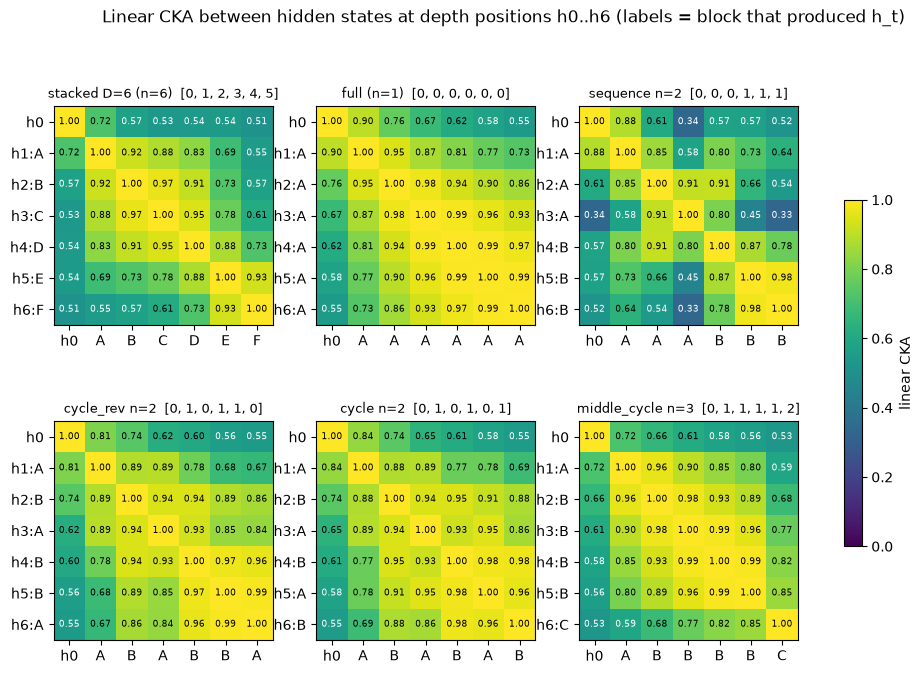

In [20]:
@torch.no_grad()
def hidden_states(model: ScheduledLM, n_windows: int = 64) -> list[torch.Tensor]:
    model.eval()
    x = torch.stack([val_ids[i * SEQ_LEN : (i + 1) * SEQ_LEN] for i in range(n_windows)])
    _, hidden = model(x, return_hidden=True)
    model.train()
    return [h.reshape(-1, h.shape[-1]).double() for h in hidden]   # each (N = 4096, d)


cka_names = ["stacked D=6 (n=6)", "full (n=1)", "sequence n=2", "cycle_rev n=2", "cycle n=2", "middle_cycle n=3"]
cka_mats, rel_update, cos_consec = {}, {}, {}
for name in cka_names:
    hs = hidden_states(results[(name, 0)]["model"])
    k = len(hs)
    cka_mats[name] = np.array([[linear_cka(hs[i], hs[j]) for j in range(k)] for i in range(k)])
    # Relative size of each block's update ||h_t - h_{t-1}|| / ||h_{t-1}|| and token-wise cosine(h_{t-1}, h_t).
    rel_update[name] = [float((hs[t] - hs[t - 1]).norm(dim=1).mean() / hs[t - 1].norm(dim=1).mean()) for t in range(1, k)]
    cos_consec[name] = [float(F.cosine_similarity(hs[t - 1], hs[t], dim=1).mean()) for t in range(1, k)]

fig, axes = plt.subplots(2, 3, figsize=(12, 7.5))
for ax, name in zip(axes.ravel(), cka_names):
    im = ax.imshow(cka_mats[name], vmin=0, vmax=1, cmap="viridis")
    sched = EXPERIMENTS[name]
    ax.set_xticks(range(7), labels=["h0"] + [f"{'ABCDEF'[s]}" for s in sched])
    ax.set_yticks(range(7), labels=["h0"] + [f"h{t + 1}:{'ABCDEF'[s]}" for t, s in enumerate(sched)])
    for i in range(7):
        for j in range(7):
            ax.text(j, i, f"{cka_mats[name][i, j]:.2f}", ha="center", va="center", fontsize=6.5,
                    color="white" if cka_mats[name][i, j] < 0.6 else "black")
    ax.set_title(f"{name}  {sched}", fontsize=9)
fig.colorbar(im, ax=axes, shrink=0.6, label="linear CKA")
fig.suptitle("Linear CKA between hidden states at depth positions h0..h6 (labels = block that produced h_t)")
plt.show()

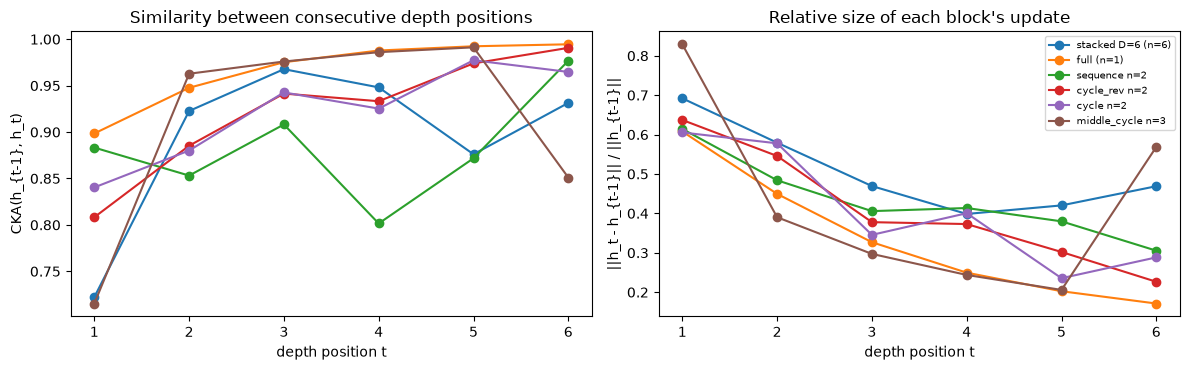

stacked D=6 (n=6)  CKA(h_t-1,h_t) = [0.722 0.923 0.968 0.948 0.876 0.931]  cos = [0.767 0.872 0.906 0.924 0.916 0.914]
full (n=1)         CKA(h_t-1,h_t) = [0.898 0.948 0.975 0.988 0.992 0.995]  cos = [0.833 0.936 0.972 0.985 0.99  0.993]
sequence n=2       CKA(h_t-1,h_t) = [0.883 0.853 0.908 0.802 0.872 0.977]  cos = [0.818 0.925 0.96  0.918 0.944 0.97 ]
cycle_rev n=2      CKA(h_t-1,h_t) = [0.808 0.885 0.941 0.933 0.974 0.991]  cos = [0.803 0.885 0.946 0.951 0.972 0.976]
cycle n=2          CKA(h_t-1,h_t) = [0.84  0.88  0.943 0.925 0.977 0.965]  cos = [0.818 0.88  0.951 0.95  0.976 0.974]
middle_cycle n=3   CKA(h_t-1,h_t) = [0.715 0.963 0.976 0.986 0.991 0.851]  cos = [0.714 0.935 0.968 0.98  0.987 0.86 ]


In [21]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8))
for name in cka_names:
    consecutive = [cka_mats[name][t, t + 1] for t in range(6)]
    ax1.plot(range(1, 7), consecutive, marker="o", label=name)
    ax2.plot(range(1, 7), rel_update[name], marker="o", label=name)
ax1.set_xlabel("depth position t")
ax1.set_ylabel("CKA(h_{t-1}, h_t)")
ax1.set_title("Similarity between consecutive depth positions")
ax2.set_xlabel("depth position t")
ax2.set_ylabel("||h_t - h_{t-1}|| / ||h_{t-1}||")
ax2.set_title("Relative size of each block's update")
ax2.legend(fontsize=7)
plt.tight_layout()
plt.show()
for name in cka_names:
    print(f"{name:18s} CKA(h_t-1,h_t) = {np.round([cka_mats[name][t, t + 1] for t in range(6)], 3)}  "
          f"cos = {np.round(cos_consec[name], 3)}")

_(conclusions are written after the first run)_

## 8. Experiments

### 8.1 Quality vs parameters at fixed depth (the core question)
Table of all configurations: mean validation bits/char over 2 seeds, the spread (|seed0 - seed1| / 2), parameter count and training time.

In [22]:
summary = []
for name, sched in EXPERIMENTS.items():
    bpcs = [results[(name, s)]["val_bpc"] for s in SEEDS]
    secs = [results[(name, s)]["hist"]["seconds"] for s in SEEDS]
    summary.append({
        "name": name, "schedule": sched, "n": n_layers_of(sched), "D": len(sched),
        "params": results[(name, 0)]["params"], "bpc": float(np.mean(bpcs)), "spread": float(np.ptp(bpcs) / 2),
        "seeds": bpcs, "sec": float(np.mean(secs)),
    })

print(f"{'config':18s} {'schedule':20s} {'n':>2s} {'D':>2s} {'params':>8s} {'val bpc (mean ± half-range)':>28s} {'seed0':>7s} {'seed1':>7s} {'train s':>8s}")
for r in summary:
    print(f"{r['name']:18s} {str(r['schedule']):20s} {r['n']:2d} {r['D']:2d} {r['params']:8,d} "
          f"{r['bpc']:20.4f} ± {r['spread']:.4f} {r['seeds'][0]:7.4f} {r['seeds'][1]:7.4f} {r['sec']:8.1f}")

SEED_NOISE = float(np.median([r["spread"] for r in summary]))
print(f"\nmedian seed half-range across configs = {SEED_NOISE:.4f} bpc  (differences smaller than ~2x this are noise)")

config             schedule              n  D   params  val bpc (mean ± half-range)   seed0   seed1  train s
stacked D=2        [0, 1]                2  2  116,736               3.7104 ± 0.0115  3.6989  3.7218     10.1
stacked D=3        [0, 1, 2]             3  3  166,720               3.5971 ± 0.0023  3.5948  3.5994     22.8
stacked D=6 (n=6)  [0, 1, 2, 3, 4, 5]    6  6  316,672               3.4309 ± 0.0127  3.4436  3.4182     43.2
full (n=1)         [0, 0, 0, 0, 0, 0]    1  6   66,752               3.7070 ± 0.0182  3.7251  3.6888     64.7
sequence n=2       [0, 0, 0, 1, 1, 1]    2  6  116,736               3.5613 ± 0.0065  3.5678  3.5548     83.0
cycle n=2          [0, 1, 0, 1, 0, 1]    2  6  116,736               3.6092 ± 0.0037  3.6129  3.6055     64.4
cycle_rev n=2      [0, 1, 0, 1, 1, 0]    2  6  116,736               3.6051 ± 0.0014  3.6037  3.6065     71.0
sequence n=3       [0, 0, 1, 1, 2, 2]    3  6  166,720               3.4987 ± 0.0032  3.4955  3.5020     67.1
cycle n=3  

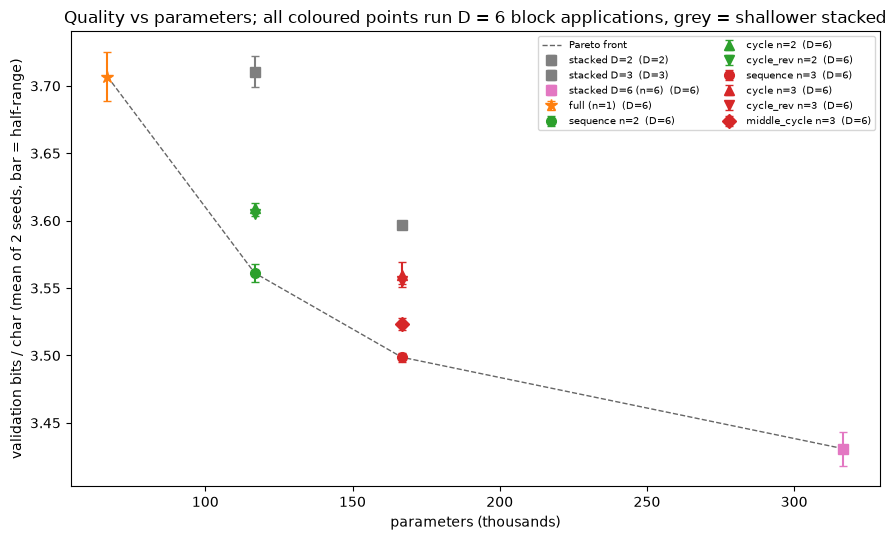

Pareto-optimal: ['full (n=1)', 'sequence n=2', 'sequence n=3', 'stacked D=6 (n=6)']


In [23]:
def pareto_front(points: list[tuple[int, float]]) -> list[int]:
    # Indices of points not dominated by any other (fewer-or-equal params AND lower-or-equal bpc).
    front = []
    for i, (p_i, b_i) in enumerate(points):
        dominated = any((p_j <= p_i and b_j <= b_i) and (p_j < p_i or b_j < b_i) for j, (p_j, b_j) in enumerate(points) if j != i)
        if not dominated:
            front.append(i)
    return sorted(front, key=lambda i: points[i][0])


markers = {"stacked": "s", "full": "*", "sequence": "o", "cycle_rev": "v", "cycle": "^", "middle": "D"}
fig, ax = plt.subplots(figsize=(9, 5.5))
for r in summary:
    family = next(k for k in ["stacked", "full", "sequence", "cycle_rev", "cycle", "middle"] if r["name"].startswith(k))
    color = "tab:gray" if family == "stacked" and r["D"] < 6 else plt.cm.tab10(r["n"] % 10)
    ax.errorbar(r["params"] / 1e3, r["bpc"], yerr=r["spread"], fmt=markers[family], ms=9 if family == "full" else 7,
                color=color, capsize=3, label=f"{r['name']}  (D={r['D']})")
pts = [(r["params"], r["bpc"]) for r in summary]
front = pareto_front(pts)
ax.plot([pts[i][0] / 1e3 for i in front], [pts[i][1] for i in front], "k--", lw=1, alpha=0.6, label="Pareto front")
ax.set_xlabel("parameters (thousands)")
ax.set_ylabel("validation bits / char (mean of 2 seeds, bar = half-range)")
ax.set_title("Quality vs parameters; all coloured points run D = 6 block applications, grey = shallower stacked")
ax.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()
print("Pareto-optimal:", [summary[i]["name"] for i in front])

In [24]:
by_name = {r["name"]: r for r in summary}


def compare(a: str, b: str) -> None:
    da = by_name[a]["bpc"] - by_name[b]["bpc"]
    noise = by_name[a]["spread"] + by_name[b]["spread"]
    both_seeds = all(results[(a, s)]["val_bpc"] < results[(b, s)]["val_bpc"] for s in SEEDS) or \
                 all(results[(a, s)]["val_bpc"] > results[(b, s)]["val_bpc"] for s in SEEDS)
    verdict = "consistent across seeds" if both_seeds and abs(da) > noise else "WITHIN NOISE"
    print(f"{a:18s} - {b:18s} = {da:+.4f} bpc   (combined spread {noise:.4f}; {verdict})")


print("Ordering at n = 2:")
compare("sequence n=2", "cycle_rev n=2")
compare("sequence n=2", "cycle n=2")
compare("cycle_rev n=2", "cycle n=2")
print("Ordering at n = 3:")
compare("sequence n=3", "cycle_rev n=3")
compare("sequence n=3", "cycle n=3")
compare("middle_cycle n=3", "sequence n=3")
print("Sharing vs shallower model with the same parameters:")
compare("sequence n=2", "stacked D=2")
compare("full (n=1)", "stacked D=2")
compare("sequence n=3", "stacked D=3")
print("Sharing vs full stacked depth 6:")
compare("sequence n=3", "stacked D=6 (n=6)")
compare("full (n=1)", "stacked D=6 (n=6)")

Ordering at n = 2:
sequence n=2       - cycle_rev n=2      = -0.0438 bpc   (combined spread 0.0079; consistent across seeds)
sequence n=2       - cycle n=2          = -0.0479 bpc   (combined spread 0.0102; consistent across seeds)
cycle_rev n=2      - cycle n=2          = -0.0041 bpc   (combined spread 0.0050; WITHIN NOISE)
Ordering at n = 3:
sequence n=3       - cycle_rev n=3      = -0.0566 bpc   (combined spread 0.0058; consistent across seeds)
sequence n=3       - cycle n=3          = -0.0613 bpc   (combined spread 0.0124; consistent across seeds)
middle_cycle n=3   - sequence n=3       = +0.0243 bpc   (combined spread 0.0077; consistent across seeds)
Sharing vs shallower model with the same parameters:
sequence n=2       - stacked D=2        = -0.1491 bpc   (combined spread 0.0179; consistent across seeds)
full (n=1)         - stacked D=2        = -0.0034 bpc   (combined spread 0.0296; WITHIN NOISE)
sequence n=3       - stacked D=3        = -0.0984 bpc   (combined spread 0.0056; co

_(conclusions are written after the first run)_

### 8.2 Sharing saves memory, not compute: measured latency
We time a forward pass (batch 32 x 64 characters, no gradient) for the trained seed-0 models and report the parameter memory in float32. If the schedule has $D = 6$ applications, the latency should be the same no matter how many blocks are owned.

In [25]:
@torch.no_grad()
def forward_ms(model: ScheduledLM, reps: int = 15) -> float:
    model.eval()
    x = torch.stack([val_ids[i * SEQ_LEN : (i + 1) * SEQ_LEN] for i in range(32)])
    model(x)  # warm-up
    times = []
    for _ in range(reps):
        t0 = time.perf_counter()
        model(x)
        times.append(time.perf_counter() - t0)
    model.train()
    return 1000 * float(np.median(times))


latency = {}
print(f"{'config':18s} {'n':>2s} {'D':>2s} {'param MB (fp32)':>16s} {'forward ms':>11s}")
for r in summary:
    model = results[(r["name"], 0)]["model"]
    latency[r["name"]] = forward_ms(model)
    print(f"{r['name']:18s} {r['n']:2d} {r['D']:2d} {4 * r['params'] / 2**20:16.3f} {latency[r['name']]:11.2f}")
d6 = [latency[r["name"]] for r in summary if r["D"] == 6]
print(f"\nD=6 models: forward time {min(d6):.2f}-{max(d6):.2f} ms although parameters differ {min(r['params'] for r in summary if r['D']==6):,}-{max(r['params'] for r in summary if r['D']==6):,}")

config              n  D  param MB (fp32)  forward ms
stacked D=2         2  2            0.445        3.45


stacked D=3         3  3            0.636        5.11


stacked D=6 (n=6)   6  6            1.208       10.16


full (n=1)          1  6            0.255       10.18


sequence n=2        2  6            0.445       10.13


cycle n=2           2  6            0.445       10.05


cycle_rev n=2       2  6            0.445       10.05


sequence n=3        3  6            0.636       10.05


cycle n=3           3  6            0.636        9.55


cycle_rev n=3       3  6            0.636        9.52


middle_cycle n=3    3  6            0.636       10.14

D=6 models: forward time 9.52-10.18 ms although parameters differ 66,752-316,672


_(conclusions are written after the first run)_

### 8.3 ALBERT's other trick: factorized embeddings
ALBERT (Lan et al., 2019) combines **cross-layer sharing** (our "full" schedule) with a **factorized embedding**: instead of a $V \times d$ table it learns a $V \times E$ table and an $E \times d$ projection with $E \ll d$. This only matters when the vocabulary is large. With our character vocabulary it is irrelevant, as the numbers show.

In [26]:
class FactorizedEmbedding(nn.Module):
    # ALBERT-style: token -> small E-dim vector -> project up to d_model.
    def __init__(self, vocab_size: int, emb_dim: int, d_model: int) -> None:
        super().__init__()
        self.small = nn.Embedding(vocab_size, emb_dim)
        self.up = nn.Linear(emb_dim, d_model, bias=False)

    def forward(self, idx: torch.Tensor) -> torch.Tensor:
        return self.up(self.small(idx))


fe = FactorizedEmbedding(tok.vocab_size, 16, D_MODEL)
assert fe(xb).shape == (4, SEQ_LEN, D_MODEL)
for V, d, E in [(tok.vocab_size, 64, 16), (30_000, 768, 128), (128_000, 4096, 512)]:
    full_table = V * d
    factorized = V * E + E * d
    print(f"V={V:>7,d} d={d:5d} E={E:4d}:  V*d = {full_table:>12,d}   V*E + E*d = {factorized:>11,d}   ({full_table / factorized:4.1f}x smaller)")
print(f"\nfor comparison, ONE transformer block at d=768 has about {12 * 768**2:,} weights")

V=     98 d=   64 E=  16:  V*d =        6,272   V*E + E*d =       2,592   ( 2.4x smaller)
V= 30,000 d=  768 E= 128:  V*d =   23,040,000   V*E + E*d =   3,938,304   ( 5.9x smaller)
V=128,000 d= 4096 E= 512:  V*d =  524,288,000   V*E + E*d =  67,633,152   ( 7.8x smaller)

for comparison, ONE transformer block at d=768 has about 7,077,888 weights


At BERT-base scale ($V$=30k, $d$=768) the embedding table (23M) is as big as two blocks, so after sharing all blocks it **dominates** the parameter count - that is why ALBERT factorizes it. For a character model ($V \approx 90$) the table is under 6k parameters and factorization buys nothing.

## 9. Common pitfalls & debugging tips

_(conclusions are written after the first run)_

## 10. Recap

_(conclusions are written after the first run)_

### Cheat sheet

| you want | do |
|---|---|
| any sharing scheme | `ScheduledLM(..., schedule=[...])`; the forward is `for j in schedule: x = layers[j](x)` |
| SEQUENCE / CYCLE / CYCLE-REV | `[t // (D//n)]`, `[t % n]`, cycle for `D-n` positions then `reversed(range(n))` |
| unshared first & last (Middle-Cycle) | `[0] + [1]*(D-2) + [2]` |
| params | $n \cdot P_{blk}$ + embeddings - set by **n** |
| compute / latency / activation memory | $\propto D$ - set by the **schedule length**, unchanged by sharing |
| gradient of a shared block | sum over its uses (checked to ~1e-7 in §4.1) |
| fair comparison | same $D$, same steps, same data order, $\ge$ 2 seeds, held-out bpc |

### Exercises
1. **Deeper schedules.** Repeat §8.1 at $D = 8$ with $n = 2$ and $n = 4$. Does the ranking of SEQUENCE vs CYCLE vs CYCLE-REV change when each block is reused fewer times?
   *Hint:* only the `DEPTH` constant and the `SCHEDULES` dict change; `schedule_sequence` needs $n \mid D$. Halve `STEPS` or use one seed to stay within time.
2. **Per-use learning rate.** A block used $k$ times gets a gradient roughly $k$ times larger (§7.1), but Adam normalizes per parameter. Try plain SGD with momentum instead of AdamW and see whether the full-sharing model becomes harder to train.
   *Hint:* replace the optimizer line in `train_lm`; keep gradient clipping and watch `history["grad_norms"]`.
3. **Relax the sharing.** Give each depth position its own tiny per-position parameters on top of the shared block (e.g. a learned scale vector of size $d$ multiplying the block's update, or a rank-4 LoRA on the MLP). How many extra parameters close the gap between `full (n=1)` and `stacked D=6`?
   *Hint:* pass the position index `t` into the block; notebook 06 (relaxed recursion) explores the LoRA version.

### References
* Takase & Kiyono, *Lessons on Parameter Sharing across Layers in Transformers*, arXiv:2104.06022 (SEQUENCE / CYCLE / CYCLE-REV).
* Lan et al., *ALBERT: A Lite BERT for Self-supervised Learning of Language Representations*, arXiv:1909.11942 (cross-layer sharing + factorized embedding).
* Dehghani et al., *Universal Transformers*, arXiv:1807.03819 (one block applied recurrently over depth).
* Bae et al., *Mixture-of-Recursions: Learning Dynamic Recursive Depths for Adaptive Token-Level Computation*, arXiv:2507.10524 (Middle-Cycle sharing with unshared first/last layers).
* Kornblith et al., *Similarity of Neural Network Representations Revisited*, arXiv:1905.00414 (linear CKA).

In [27]:
total = time.time() - NOTEBOOK_START
print(f"total notebook runtime: {total / 60:.1f} min")

total notebook runtime: 19.8 min
